In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

import matplotlib.pyplot as plt

In [5]:
import pandas as pd

churn_data = pd.read_csv(
    "../002.DataPrepration/Customer_Churn_Prepared.csv",
    parse_dates=["ReferenceDate", "FirstPurchase", "LastPurchase"]
)

print("Dataset shape:", churn_data.shape)
print("\nColumns:")
print(churn_data.columns.tolist())

print("\nFirst 5 rows:")
display(churn_data.head())

Dataset shape: (10926, 14)

Columns:
['CustomerID', 'FirstPurchase', 'LastPurchase', 'TotalSpend', 'TotalUnits', 'UniqueProducts', 'ActiveDays', 'Frequency', 'AverageInvoiceValue', 'Recency', 'TenureDays', 'AverageDaysBetweenPurchases', 'ReferenceDate', 'Churn']

First 5 rows:


,CustomerID,FirstPurchase,LastPurchase,TotalSpend,TotalUnits,UniqueProducts,ActiveDays,Frequency,AverageInvoiceValue,Recency,TenureDays,AverageDaysBetweenPurchases,ReferenceDate,Churn
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.60,74215,1,1,1,77183.600000,134,0,NaN,2011-06-01,1
1,12347,2010-12-07 14:57:00,2011-04-07 10:43:00,1823.43,1117,63,3,3,607.810000,55,121,60.411806,2011-06-01,0
2,12348,2010-12-16 19:09:00,2011-04-05 10:47:00,1487.24,2124,22,3,3,495.746667,57,110,54.825694,2011-06-01,1
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,334.40,197,17,1,1,334.400000,119,0,NaN,2011-06-01,1
4,12352,2011-02-16 12:33:00,2011-03-22 16:08:00,1561.81,254,26,4,5,312.362000,71,34,8.537326,2011-06-01,1


In [6]:
print("Dataset information:")
churn_data.info()

print("\nMissing values per column:")
print(churn_data.isnull().sum())

print("\nTarget distribution:")
print(churn_data["Churn"].value_counts())

print("\nTarget distribution (percentage):")
print(
    (churn_data["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10926 entries, 0 to 10925
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   CustomerID                   10926 non-null  int64         
 1   FirstPurchase                10926 non-null  datetime64[us]
 2   LastPurchase                 10926 non-null  datetime64[us]
 3   TotalSpend                   10926 non-null  float64       
 4   TotalUnits                   10926 non-null  int64         
 5   UniqueProducts               10926 non-null  int64         
 6   ActiveDays                   10926 non-null  int64         
 7   Frequency                    10926 non-null  int64         
 8   AverageInvoiceValue          10926 non-null  float64       
 9   Recency                      10926 non-null  int64         
 10  TenureDays                   10926 non-null  int64         
 11  AverageDaysBetweenPurchases  57

In [7]:
import pandas as pd

model_data = churn_data.loc[
    churn_data["ReferenceDate"] == pd.Timestamp("2011-06-01")
].copy()

feature_columns = [
    "TotalSpend",
    "TotalUnits",
    "UniqueProducts",
    "ActiveDays",
    "Frequency",
    "AverageInvoiceValue",
    "Recency",
    "TenureDays",
    "AverageDaysBetweenPurchases"
]

X = model_data[feature_columns].copy()
y = model_data["Churn"].copy()

print("Modeling dataset shape:", model_data.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Modeling dataset shape: (2659, 14)
Features shape: (2659, 9)
Target shape: (2659,)

Target distribution:
Churn
0    1331
1    1328
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train shape: (2127, 9)
X_test shape: (532, 9)
y_train shape: (2127,)
y_test shape: (532,)

Training target distribution:
Churn
0    1065
1    1062
Name: count, dtype: int64

Testing target distribution:
Churn
0    266
1    266
Name: count, dtype: int64


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

print(rf_pipeline)

Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=200,
                                        n_jobs=-1, random_state=42))])


In [10]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [11]:
y_pred = rf_pipeline.predict(X_test)

print("First 20 actual labels:")
print(y_test.head(20).to_list())

print("\nFirst 20 predicted labels:")
print(y_pred[:20])

print("\nNumber of predictions:", len(y_pred))

First 20 actual labels:
[0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1]

First 20 predicted labels:
[1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1]

Number of predictions: 532


Classification Report:
              precision    recall  f1-score   support

No Churn (0)       0.69      0.64      0.66       266
   Churn (1)       0.66      0.71      0.69       266

    accuracy                           0.68       532
   macro avg       0.68      0.68      0.68       532
weighted avg       0.68      0.68      0.68       532


Confusion Matrix:
[[170  96]
 [ 76 190]]


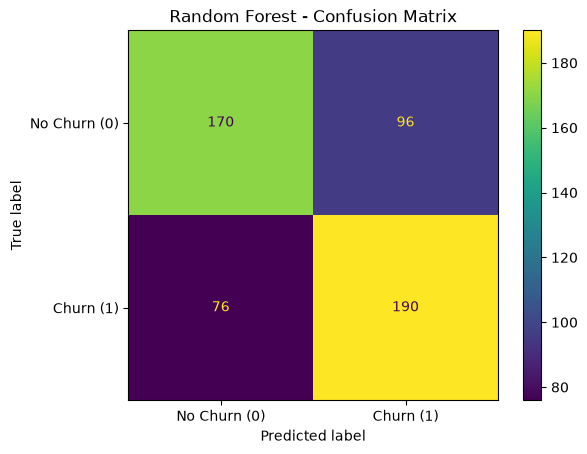

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn (0)", "Churn (1)"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn (0)", "Churn (1)"]
)

display.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [13]:
from sklearn.metrics import roc_auc_score, average_precision_score


y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)

avg_precision = average_precision_score(y_test, y_proba)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")

ROC-AUC: 0.7114
Average Precision: 0.6664
